# Graph Search: BFS, DFS and Dijkstra

BFS and DFS are implemented on a small graph. Dijkstra's algorithm is implemented on a real road network: the city of **Oldenburg, Germany**,
generated by T. Brinkhoff's network-based moving-objects generator and distributed by Feifei Li. Every node is a road intersection and
every edge is a road segment whose weight is its length. The source and the destination are preset for every task.

| File | Contains | Columns |
|---|---|---|
| `OL.cnode` | Intersections (nodes) | node id, x, y |
| `OL.cedge` | Road segments (edges) | edge id, start node, end node, length |

Download both files into `ASSIGNMENT_2/InClass/data/`:

- <https://users.cs.utah.edu/~lifeifei/research/tpq/OL.cnode>
- <https://users.cs.utah.edu/~lifeifei/research/tpq/OL.cedge>

**Rules:** implement every search algorithm yourself, using only the graph itself (its nodes, edges and weights). Library search functions may be used only to check your results. Use **NetworkX** to create, store and
**visualize** the graphs. Print every result asked for in a task.

In [1]:
import heapq
import math
import os
import urllib.request
from collections import deque

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

data_dir = "../data"
base_url = "https://users.cs.utah.edu/~lifeifei/research/tpq"

# Download the two road network files once (skipped if they are already in the data folder)
os.makedirs(data_dir, exist_ok=True)
for fname in ["OL.cnode", "OL.cedge"]:
    if not os.path.exists(os.path.join(data_dir, fname)):
        urllib.request.urlretrieve(f"{base_url}/{fname}", os.path.join(data_dir, fname))

### The small graph (Exercise 1)

The cell below creates the graph used for BFS and DFS: a **fixed**, connected, undirected graph with 15 nodes, numbered 0 to 14.
The seed is fixed, so everybody gets the same graph. The source and the destination are preset, and `small_pos` holds fixed node positions for drawing.
Run the cell; you do not need to change it.

In [2]:
small = nx.gnp_random_graph(15, 0.2, seed=43)     # fixed seed: the same graph for everybody
assert nx.is_connected(small)
small_pos = nx.spring_layout(small, seed=42)      # fixed positions for drawing

src, dest = 0, 13                                 # preset source and destination

### Exercise 1: BFS and DFS

Source: node `0`. Destination: node `13`.

1. Load the small graph and print its number of nodes and edges.
2. Implement `bfs(G, src, dest)` and `dfs(G, src, dest)`. Each returns `(path, order)`: the path from `src` to `dest` and the list of nodes in the order they were expanded.
   Consider the neighbours of a node in increasing order of node id (DFS visits the smallest unvisited neighbour first).
   For each, print the path, its distance (number of edges) and the expansion order.
3. Using **NetworkX**, visualize the graph twice, highlighting the BFS path and the DFS path. Show `src` and `dest` in different colours.

nodes: 15 edges: 25
BFS path: [0, 3, 14, 12, 13]
BFS distance: 4
BFS expansion order: [0, 1, 3, 9, 7, 2, 4, 11, 14, 5, 8, 10, 6, 12, 13]
DFS path: [0, 1, 3, 2, 4, 7, 5, 11, 6, 12, 13]
DFS distance: 10
DFS expansion order: [0, 1, 3, 2, 4, 7, 5, 10, 11, 6, 8, 12, 13]


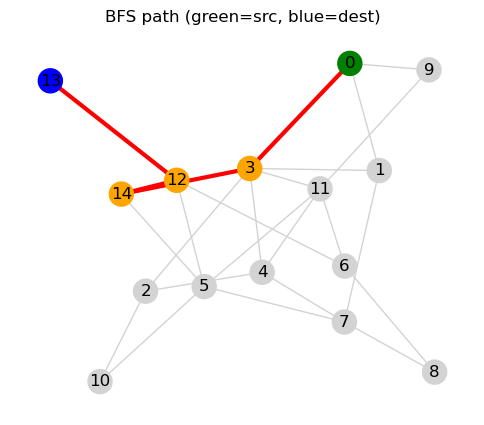

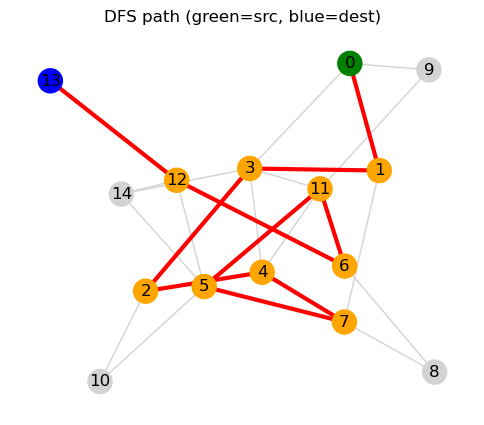

In [3]:
# 1. small graph
print("nodes:",small.number_of_nodes(),"edges:",small.number_of_edges())

# 2. bfs and dfs
def trace(par,t):
    p=[t]
    while par[p[-1]] is not None:
        p.append(par[p[-1]])
    return p[::-1]

def bfs(G,src,dest):
    par={src:None}
    q=deque([src])
    order=[]
    while q:
        u=q.popleft()
        order.append(u)
        if u==dest:
            return trace(par,dest),order
        for v in sorted(G[u]):
            if v not in par:
                par[v]=u
                q.append(v)
    return None,order

def dfs(G,src,dest):
    par={}
    seen=set()
    order=[]
    st=[(src,None)]
    while st:
        u,p=st.pop()
        if u in seen:
            continue
        seen.add(u)
        par[u]=p
        order.append(u)
        if u==dest:
            return trace(par,dest),order
        for v in sorted(G[u],reverse=True):
            if v not in seen:
                st.append((v,u))
    return None,order

bp,bo=bfs(small,src,dest)
dp,do=dfs(small,src,dest)
for name,p,o in [("BFS",bp,bo),("DFS",dp,do)]:
    print(name,"path:",p)
    print(name,"distance:",len(p)-1)
    print(name,"expansion order:",o)

# 3. draw
def show(p,name):
    plt.figure(figsize=(6,5))
    nx.draw_networkx_edges(small,small_pos,edge_color="lightgray")
    nx.draw_networkx_edges(small,small_pos,edgelist=list(zip(p,p[1:])),edge_color="red",width=3)
    col=["green" if n==src else "blue" if n==dest else "orange" if n in p else "lightgray" for n in small]
    nx.draw_networkx_nodes(small,small_pos,node_color=col)
    nx.draw_networkx_labels(small,small_pos)
    plt.title(name)
    plt.axis("off")
    plt.show()

show(bp,"BFS path (green=src, blue=dest)")
show(dp,"DFS path (green=src, blue=dest)")

### Provided for Exercise 2: preset source and destination

The **source** (node `100`) and the **destination** (node `6000`) are preset node ids of the road network, the same for everybody. Run the cell; you do not need to change it.

In [4]:
ROAD_SRC = 100         # preset source node id (from OL.cnode)
ROAD_DEST = 6000       # preset destination node id (from OL.cnode)

### Exercise 2: Dijkstra on the road network

Source: node `100`. Destination: node `6000`.

> **What is a connected component?** A connected component is a maximal set of nodes in which every node can be reached from every other node by following edges.
> A graph can have several components (for example, a few roads that are not linked to the rest of the network), and a route exists only between two nodes of the same component.
> Keep only the largest one.

1. Load the road network, keep only its largest connected component and print its number of nodes, number of edges and total road length.
2. Implement `dijkstra(G, src, dest)` following Algorithm 1 of the handout; it returns `(path, cost, expanded)`.
   Print the route length and the number of expanded nodes, and check the route length against a library function.
3. Using **NetworkX**, visualize the road network with the route highlighted. Show the source and the destination in different colours.

full graph: 6105 nodes, 7029 edges
nodes: 6105 edges: 7029 total road length: 518244.69
route length: 6126.95
expanded nodes: 3535
hops in route: 91
networkx route length: 6126.95 | match: True


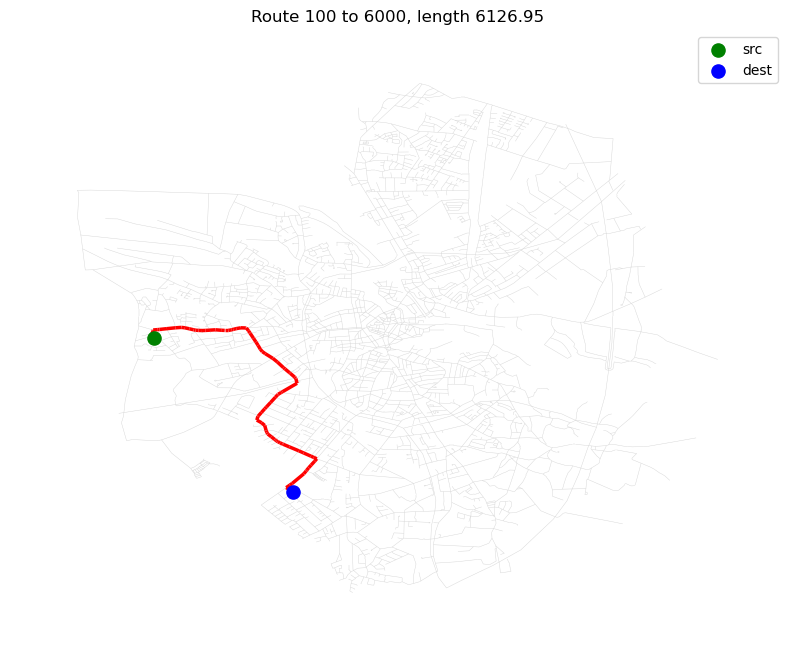

In [5]:
# 1. load, keep the largest component
cn=np.loadtxt(f"{data_dir}/OL.cnode")
ce=np.loadtxt(f"{data_dir}/OL.cedge")
R=nx.Graph()
for i,x,y in cn:
    R.add_node(int(i),pos=(x,y))
for _,a,b,w in ce:
    R.add_edge(int(a),int(b),weight=w)
print("full graph:",R.number_of_nodes(),"nodes,",R.number_of_edges(),"edges")
big=max(nx.connected_components(R),key=len)
R=R.subgraph(big).copy()
tot=sum(d["weight"] for _,_,d in R.edges(data=True))
print("nodes:",R.number_of_nodes(),"edges:",R.number_of_edges(),"total road length:",round(tot,2))

# 2. dijkstra (Algorithm 1)
def rebuild(par,t):
    p=[t]
    while par[p[-1]] is not None:
        p.append(par[p[-1]])
    return p[::-1]

def dijkstra(G,src,dest):
    dist={v:math.inf for v in G}
    dist[src]=0
    par={src:None}
    pq=[(0,src)]
    closed=set()
    while pq:
        d,u=heapq.heappop(pq)
        if u in closed:
            continue
        closed.add(u)
        if u==dest:
            return rebuild(par,dest),dist[dest],len(closed)
        for v in G[u]:
            w=G[u][v]["weight"]
            if dist[u]+w<dist[v]:
                dist[v]=dist[u]+w
                par[v]=u
                heapq.heappush(pq,(dist[v],v))
    return None,math.inf,len(closed)

path,cost,exp=dijkstra(R,ROAD_SRC,ROAD_DEST)
print("route length:",round(cost,2))
print("expanded nodes:",exp)
print("hops in route:",len(path)-1)
lib=nx.dijkstra_path_length(R,ROAD_SRC,ROAD_DEST,weight="weight")
print("networkx route length:",round(lib,2),"| match:",math.isclose(cost,lib))

# 3. draw
pos=nx.get_node_attributes(R,"pos")
plt.figure(figsize=(10,8))
nx.draw_networkx_edges(R,pos,width=0.3,edge_color="lightgray")
nx.draw_networkx_edges(R,pos,edgelist=list(zip(path,path[1:])),edge_color="red",width=2.5)
nx.draw_networkx_nodes(R,pos,nodelist=[ROAD_SRC],node_color="green",node_size=90,label="src")
nx.draw_networkx_nodes(R,pos,nodelist=[ROAD_DEST],node_color="blue",node_size=90,label="dest")
plt.legend()
plt.title(f"Route {ROAD_SRC} to {ROAD_DEST}, length {cost:.2f}")
plt.axis("off")
plt.show()

**Before you submit:** run **Kernel → Restart & Run All** so that all outputs are visible, then push the notebook, the data files and the updated `environment.yml` and `requirements.txt` to your repository.